# Lecture 7: Targeting the Right Customers
## Predictive Targeting with Logistic Regression

---

### Learning Objectives

By completing this notebook you will be able to:

1. Explore a customer targeting dataset and visualise relationships between predictors and purchase behaviour
2. Perform model selection using cross-validation across all predictor combinations
3. Fit and interpret a logistic regression model using statsmodels
4. Evaluate classification performance using confusion matrices, ROC curves, and AUC
5. Build and interpret a lift chart to determine optimal targeting depth

### Dataset

We use a customer targeting dataset with 502 customers:

| Variable | Description |
|----------|-------------|
| `custid` | Unique customer identifier |
| `Purch` | Whether the customer made a purchase (1 = Yes, 0 = No) |
| `HHINCOME` | Household income |
| `HHSIZE` | Household size |
| `MARKCAMP` | Whether the customer was targeted by a marketing campaign (1 = Yes, 0 = No) |

---
## 0. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

DATA_PATH = '../data/targeting.csv'

---
## 1. Load and Explore the Data

### Task 1.1: Load the dataset

Load `targeting.csv` into a DataFrame. Drop the `custid` column (it is just an identifier) and any unnamed index columns. Display the first few rows.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=['custid'] + [col for col in df.columns if col.startswith('Unnamed')])
df.head()

,Purch,HHINCOME,HHSIZE,MARKCAMP
0,1,132905.142171,5,0
1,1,203873.536743,3,0
2,1,227455.251667,1,1
3,1,239057.755450,1,0
4,1,283117.159133,1,0


### Task 1.2: Visualise HHINCOME by purchase status

Create a boxplot of `HHINCOME` grouped by `Purch` to see if household income differs between purchasers and non-purchasers.

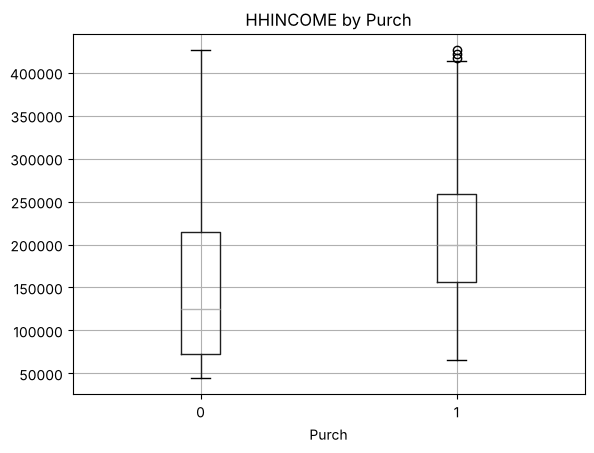

In [3]:
df.boxplot(column='HHINCOME', by='Purch')
plt.title('HHINCOME by Purch'); plt.suptitle(''); plt.show()

### Task 1.3: Visualise HHSIZE vs purchase rate

Create a side-by-side bar plot showing the percentage of purchasers vs non-purchasers for each household size.

**Hint:** Use `pd.crosstab()` with `normalize='index'` to get percentages.

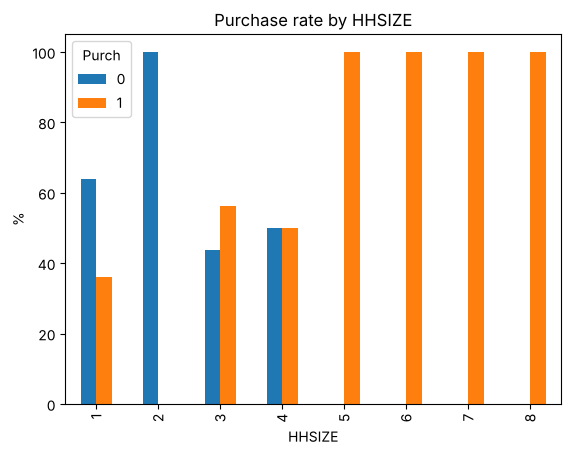

In [4]:
(pd.crosstab(df.HHSIZE, df.Purch, normalize='index') * 100).plot(kind='bar')
plt.ylabel('%'); plt.title('Purchase rate by HHSIZE'); plt.show()

### Task 1.4: Visualise MARKCAMP vs purchase rate

Do the same for `MARKCAMP` — does being targeted by a marketing campaign change the purchase rate?

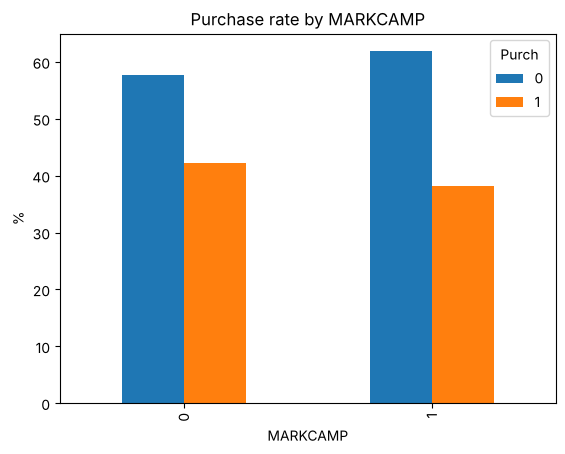

In [5]:
(pd.crosstab(df.MARKCAMP, df.Purch, normalize='index') * 100).plot(kind='bar')
plt.ylabel('%'); plt.title('Purchase rate by MARKCAMP'); plt.show()

### Discussion

**Answer the following:**
- Does household income appear to differ between purchasers and non-purchasers?
- Which household sizes have the highest purchase rates?
- Does the marketing campaign appear to be associated with higher purchase rates?

- **Income:** yes. Buyers earn more (median ~200k vs ~125k). Almost nobody under 110k buys (1%), but it isn't linear: the very top incomes (300k+) buy a bit less than the 200–300k group.
- **Household size:** households of 5+ bought 100% of the time, and 3–4 people about 50%. Singles (85% of the base) sit at 36%, and 2-person households never bought.
- **Campaign:** no. If anything, targeted customers bought slightly less (38% vs 42%). The campaign doesn't seem to be doing much.

---
## 2. Model Selection via Cross-Validation

We want to find the best combination of predictors for our logistic regression. We will try **all possible combinations** of the three predictors (`HHINCOME`, `HHSIZE`, `MARKCAMP`) and evaluate each using **10-fold cross-validation**.

### Task 2.1: Cross-validate all predictor combinations

For each combination:
1. Run 10-fold cross-validation with `LogisticRegression`
2. Compute average accuracy, sensitivity (recall), and specificity across folds
3. Print the results

**Hint:** Use `itertools.combinations` to generate all subsets. Use `sklearn.model_selection.KFold` for cross-validation.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, accuracy_score
from itertools import combinations

PREDS = ['HHINCOME', 'HHSIZE', 'MARKCAMP']
y = df.Purch
kf = KFold(n_splits=10, shuffle=True, random_state=42)

def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return accuracy_score(y_true, y_pred), tp / (tp + fn), tn / (tn + fp)

def cv_all(make_model):
    rows = []
    for k in range(1, 4):
        for cols in combinations(PREDS, k):
            X = df[list(cols)]
            m = [metrics(y.iloc[te], make_model().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]))
                 for tr, te in kf.split(X)]
            rows.append([' + '.join(cols), *np.mean(m, axis=0)])
    return pd.DataFrame(rows, columns=['predictors', 'accuracy', 'sensitivity', 'specificity']).round(3)

cv_all(lambda: LogisticRegression(max_iter=1000))

,predictors,accuracy,sensitivity,specificity
0,HHINCOME,0.602,0.317,0.789
1,HHSIZE,0.656,0.243,0.940
2,MARKCAMP,0.598,0.000,1.000
3,HHINCOME + HHSIZE,0.654,0.382,0.835
4,HHINCOME + MARKCAMP,0.600,0.316,0.785
5,HHSIZE + MARKCAMP,0.660,0.243,0.944
6,HHINCOME + HHSIZE + MARKCAMP,0.660,0.399,0.836


### Discussion

**Answer the following:**
- Which combination of predictors gives the best accuracy? The best sensitivity?
- Why might a model with fewer predictors be preferred even if accuracy is slightly lower?
- Which combination will you use going forward, and why?

- **Best accuracy:** all three predictors and HHSIZE + MARKCAMP tie at 0.660. **Best sensitivity:** all three (0.399), with HHINCOME + HHSIZE right behind (0.382).
- **Why fewer predictors:** simpler models are easier to explain, less likely to overfit, and cheaper to maintain. If a variable adds nothing, it's just noise.
- **Choice: HHINCOME + HHSIZE.** It's basically as good as the full model (0.654 vs 0.660 accuracy, 0.382 vs 0.399 sensitivity). MARKCAMP adds almost nothing and the EDA showed no link to purchase. Dropping HHINCOME kills sensitivity (0.24), so income has to stay.

---
## 3. Fitting the Selected Model

Now fit your chosen model on the **full dataset** using `statsmodels` (which provides detailed statistical summaries including p-values and confidence intervals).

### Task 3.1: Fit a logistic regression with statsmodels

Use `sm.Logit()` with your selected predictors. Print the model summary.

**Hint:** Remember to add a constant with `sm.add_constant()`.

In [7]:
import statsmodels.api as sm

SEL = ['HHINCOME', 'HHSIZE']
X = sm.add_constant(df[SEL])
logit = sm.Logit(y, X).fit()
print(logit.summary())
print('Odds ratios:'); print(np.exp(logit.params))

Optimization terminated successfully.
         Current function value: 0.580231
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  Purch   No. Observations:                  502
Model:                          Logit   Df Residuals:                      499
Method:                           MLE   Df Model:                            2
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.1391
Time:                        14:35:02   Log-Likelihood:                -291.28
converged:                       True   LL-Null:                       -338.33
Covariance Type:            nonrobust   LLR p-value:                 3.661e-21
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.4260      0.257     -9.430      0.000      -2.930      -1.922
HHINCOME    6.657e-06   1.06e

### Task 3.2: Interpret the coefficients

For each significant predictor:
- What is the sign of the coefficient? What does it mean?
- Compute the odds ratio ($e^{\beta}$). How does a one-unit change in the predictor affect the odds of purchase?

Both predictors are positive and highly significant (p < 0.001).
- **HHINCOME (+6.7e-6):** more income means more likely to buy. The odds ratio per euro is ~1.000007, which is too small to read, so scale it up: every **+10k income multiplies the odds of purchase by ~1.07 (+7%)**.
- **HHSIZE (+0.565):** bigger households buy more. Each extra member multiplies the odds by **1.76 (+76%)**.

---
## 4. Model Evaluation

### Task 4.1: Confusion matrix and classification metrics

Using a threshold of 0.5:
1. Generate predicted classes from the model's predicted probabilities
2. Compute and print the confusion matrix
3. Calculate accuracy, sensitivity (recall), and specificity

In [8]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

p_lr = logit.predict(X)
yhat_lr = (p_lr >= 0.5).astype(int)
print(confusion_matrix(y, yhat_lr))
acc_lr, sens_lr, spec_lr = metrics(y, yhat_lr)
print(f'Accuracy {acc_lr:.3f} | Sensitivity {sens_lr:.3f} | Specificity {spec_lr:.3f}')

[[252  48]
 [123  79]]
Accuracy 0.659 | Sensitivity 0.391 | Specificity 0.840


### Task 4.2: ROC curve and AUC

Plot the ROC curve and compute the AUC score. Include:
- The ROC curve itself
- The diagonal baseline (random classifier)
- The AUC value in the legend

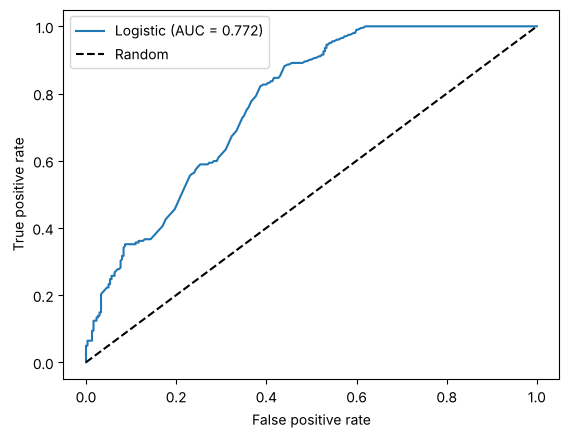

In [9]:
def plot_roc(curves):
    for name, p in curves.items():
        fpr, tpr, _ = roc_curve(y, p)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y, p):.3f})')
    plt.plot([0, 1], [0, 1], 'k--', label='Random')
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); plt.show()

auc_lr = roc_auc_score(y, p_lr)
plot_roc({'Logistic': p_lr})

### Discussion

**Answer the following:**
- Is the model's accuracy a good measure of performance for this dataset? Why or why not?
- What does the AUC tell you about the model's discriminative ability?
- If targeting costs money, would you prefer higher precision or higher recall? Why?

- **Accuracy?** Not really. 60% of customers don't buy, so a model saying "nobody buys" already gets 60%. Ours gets 66% but only catches 39% of buyers. Sensitivity and AUC tell the real story.
- **AUC = 0.77:** decent discrimination. Pick a random buyer and a random non-buyer, and 77% of the time the model ranks the buyer higher. That's useful, though far from perfect.
- **Precision or recall?** If every contact costs money, **precision**: you don't want to pay to reach people who won't buy. If the margin per sale is much bigger than the contact cost, recall matters more, because a missed buyer costs more than a wasted mailing. In practice it depends on the cost/margin ratio.

---
## 5. Lift Chart

A lift chart evaluates how much better your model is at identifying purchasers compared to random targeting.

### Task 5.1: Add predicted probabilities to the dataset

Use the fitted model to predict purchase probabilities for all customers. Add these as a new column `Predicted_Probability` in your DataFrame.

In [10]:
df['Predicted_Probability'] = p_lr
df['Predicted_Class'] = yhat_lr
df.head()

,Purch,HHINCOME,HHSIZE,MARKCAMP,Predicted_Probability,Predicted_Class
0,1,132905.142171,5,0,0.783301,1
1,1,203873.536743,3,0,0.651796,1
2,1,227455.251667,1,1,0.414214,0
3,1,239057.755450,1,0,0.433070,0
4,1,283117.159133,1,0,0.505991,1


### Task 5.2: Build the lift chart table

Steps:
1. Sort customers by predicted probability (descending)
2. Divide into 10 equal groups (deciles)
3. For each decile, compute:
   - Observed purchases
   - Cumulative observed purchases
   - Expected purchases (if random)
   - Cumulative expected purchases
   - Lift (observed / expected)
   - Difference (cumulative observed - cumulative expected)

**Hint:** Use `pd.qcut()` to create decile groups.

In [11]:
def lift_table(p):
    d = pd.DataFrame({'y': y, 'p': p}).sort_values('p', ascending=False).reset_index(drop=True)
    d['decile'] = pd.qcut(d.index, 10, labels=range(1, 11))
    t = d.groupby('decile', observed=True).agg(n=('y', 'size'), observed=('y', 'sum'))
    t['cum_observed'] = t.observed.cumsum()
    t['expected'] = t.n * y.mean()
    t['cum_expected'] = t.expected.cumsum()
    t['lift'] = t.observed / t.expected
    t['cum_lift'] = t.cum_observed / t.cum_expected
    t['difference'] = t.cum_observed - t.cum_expected
    return t.round(2)

lift_lr = lift_table(p_lr)
lift_lr

,n,observed,cum_observed,expected,cum_expected,lift,cum_lift,difference
decile,,,,,,,,
1,51,41,41,20.52,20.52,2.00,2.00,20.48
2,50,30,71,20.12,40.64,1.49,1.75,30.36
3,50,21,92,20.12,60.76,1.04,1.51,31.24
4,50,28,120,20.12,80.88,1.39,1.48,39.12
5,50,27,147,20.12,101.00,1.34,1.46,46.00
6,50,25,172,20.12,121.12,1.24,1.42,50.88
7,50,19,191,20.12,141.24,0.94,1.35,49.76
8,50,11,202,20.12,161.36,0.55,1.25,40.64
9,50,0,202,20.12,181.48,0.00,1.11,20.52


### Task 5.3: Plot the cumulative lift chart

Create a plot with:
- X-axis: decile (1 to 10)
- Y-axis: cumulative purchases
- Two lines: model (observed) vs random (expected)
- Annotate the point of maximum difference

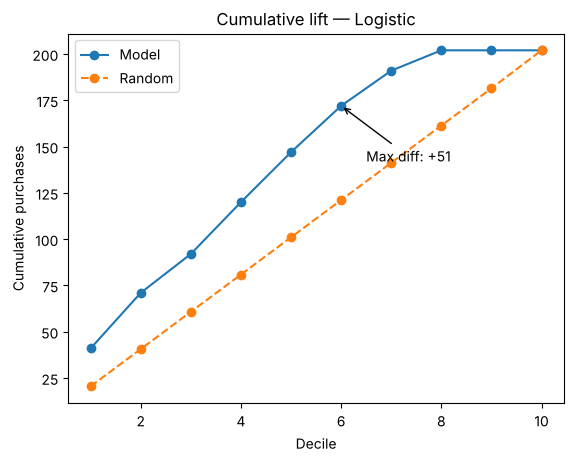

In [12]:
def plot_lift(t, title):
    plt.plot(t.index, t.cum_observed, 'o-', label='Model')
    plt.plot(t.index, t.cum_expected, 'o--', label='Random')
    best = t.difference.idxmax()
    plt.annotate(f'Max diff: +{t.difference[best]:.0f}', (best, t.cum_observed[best]),
                 xytext=(best + 0.5, t.cum_observed[best] - 30), arrowprops=dict(arrowstyle='->'))
    plt.xlabel('Decile'); plt.ylabel('Cumulative purchases'); plt.title(title); plt.legend(); plt.show()

plot_lift(lift_lr, 'Cumulative lift — Logistic')

### Discussion

**Answer the following:**
- At which decile is the maximum difference between cumulative observed and expected purchases? What does this mean for targeting?
- What is the lift in the top decile? Interpret this number in business terms.
- If you could only target 40% of customers, how many of the total purchasers would you capture?
- How would you use this analysis to recommend a campaign size to a Head of Marketing?

- **Max difference:** decile 6, with +51 buyers over random. Targeting the top 60% captures 172 of 202 buyers (85%). Beyond that, each extra decile brings fewer buyers than random would, so it's not worth it.
- **Top-decile lift = 2.0:** the best-scored 10% buy at twice the average rate (41 of 51 = 80% vs a 40% base rate). Every euro spent there is twice as productive as a random mailing.
- **40% of customers:** 120 of 202 buyers (59%), vs ~81 if random.
- **For the Head of Marketing:** show the cumulative curve and pair it with costs. With the margin per sale and the cost per contact, pick the decile where the next group stops paying for itself. Without that data, 60% is the natural cut-off, and if budget is tight, 20–40% still gives 1.5–1.75× random.

---
## 6. Designing a Targeting Strategy

Using your lift chart, model evaluation, and exploratory analysis, design a data-driven targeting strategy.

### Task 6.1: Campaign recommendations

Based on your analysis, answer:
- **How many customers should be targeted?** Justify with the lift chart.
- **What customer profile should be targeted?** Use the model coefficients to describe the ideal target.
- **What is the expected uplift vs random targeting?** Quantify using the lift chart numbers.
- **What are the risks?** What happens if the model is wrong (false positives / false negatives)?

- **How many:** the top ~60% (~300 customers) captures 85% of buyers. On a tight budget, the top 20% (100 people) already brings 71 buyers, 35% of the total, at 1.75× lift.
- **Profile:** mid-to-high income (roughly 110k–300k) and larger households (3+, especially 5+). Under 110k is basically a waste of money.
- **Uplift:** at 60%, +51 buyers vs random (172 vs 121, +42%). At 20%, +30 (71 vs 41).
- **Risks:** *False positives* mean money spent on people who won't buy (only 39% of buyers are caught at the 0.5 cutoff, and many flagged customers don't convert). *False negatives* mean lost sales, e.g. high-income singles the model underrates. Also, the model isn't linear in income while the data is (the top earners buy less), and the current campaign shows no effect. Better to test with a control group before scaling up.

---
## 7. XGBoost Model

Let's repeat the prediction exercise using XGBoost, a powerful gradient boosting algorithm, and compare its performance to the logistic regression model.

### Task 7.1: Cross-validate XGBoost with all predictor combinations

Repeat the cross-validation from Section 2, but this time using `XGBClassifier` instead of `LogisticRegression`. Use the same 10-fold CV setup and evaluate all 7 predictor combinations.

**Hint:** Use `XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, eval_metric='logloss', random_state=42)`.

In [13]:
from xgboost import XGBClassifier

make_xgb = lambda: XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                                 eval_metric='logloss', random_state=42)
cv_all(make_xgb)

,predictors,accuracy,sensitivity,specificity
0,HHINCOME,0.695,0.714,0.674
1,HHSIZE,0.663,0.221,0.963
2,MARKCAMP,0.598,0.000,1.000
3,HHINCOME + HHSIZE,0.683,0.666,0.686
4,HHINCOME + MARKCAMP,0.691,0.722,0.660
5,HHSIZE + MARKCAMP,0.677,0.217,0.990
6,HHINCOME + HHSIZE + MARKCAMP,0.687,0.672,0.690


### Task 7.2: Fit the best XGBoost model and evaluate

Select the best predictor combination from the cross-validation results. Fit the XGBoost model on the full dataset and evaluate it:
1. Print the confusion matrix
2. Compute accuracy, sensitivity, and specificity

In [14]:
# HHINCOME alone edges CV accuracy by ~1pp; keeping HHSIZE gives a like-for-like comparison with the logit
SEL_XGB = ['HHINCOME', 'HHSIZE']
xgb_model = make_xgb().fit(df[SEL_XGB], y)
p_xgb = xgb_model.predict_proba(df[SEL_XGB])[:, 1]
yhat_xgb = xgb_model.predict(df[SEL_XGB])
print(confusion_matrix(y, yhat_xgb))
acc_xgb, sens_xgb, spec_xgb = metrics(y, yhat_xgb)
print(f'Accuracy {acc_xgb:.3f} | Sensitivity {sens_xgb:.3f} | Specificity {spec_xgb:.3f}')

[[224  76]
 [ 39 163]]
Accuracy 0.771 | Sensitivity 0.807 | Specificity 0.747


### Task 7.3: Feature importance

Plot the feature importances from the fitted XGBoost model as a horizontal bar chart.

**Hint:** Use `xgb_model.feature_importances_` and `plt.barh()`.

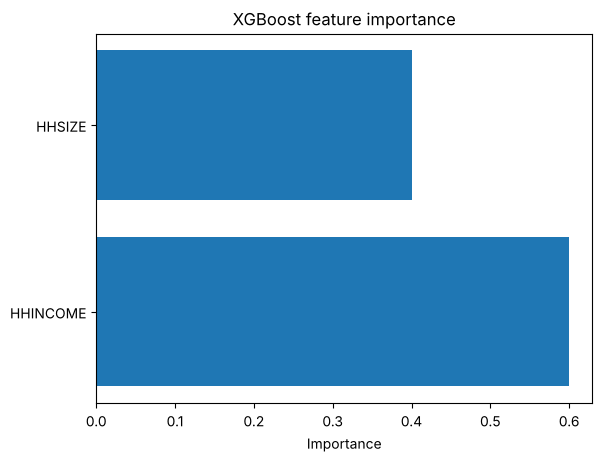

In [15]:
plt.barh(SEL_XGB, xgb_model.feature_importances_)
plt.xlabel('Importance'); plt.title('XGBoost feature importance'); plt.show()

### Task 7.4: ROC curve and AUC

Plot the ROC curve for the XGBoost model and compute the AUC score. Include the diagonal baseline and AUC value in the legend.

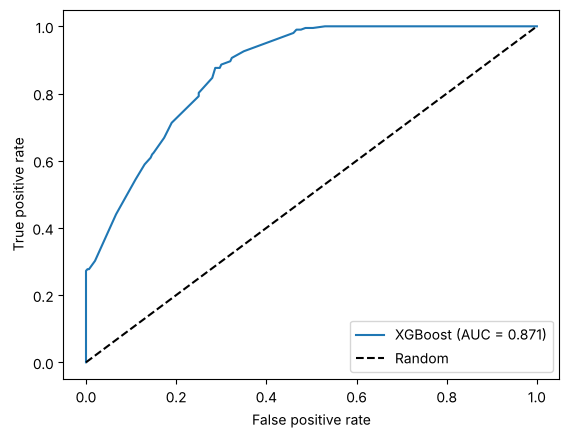

In [16]:
auc_xgb = roc_auc_score(y, p_xgb)
plot_roc({'XGBoost': p_xgb})

### Task 7.5: XGBoost Lift Chart

Repeat the lift chart analysis from Section 5, but using the XGBoost model's predicted probabilities:
1. Sort customers by XGBoost predicted probability (descending)
2. Divide into 10 deciles
3. Build the lift chart table (observed, expected, cumulative, lift)
4. Plot the cumulative lift chart (model vs random)

,n,observed,cum_observed,expected,cum_expected,lift,cum_lift,difference
decile,,,,,,,,
1,51,51,51,20.52,20.52,2.49,2.49,30.48
2,50,33,84,20.12,40.64,1.64,2.07,43.36
3,50,30,114,20.12,60.76,1.49,1.88,53.24
4,50,30,144,20.12,80.88,1.49,1.78,63.12
5,50,25,169,20.12,101.00,1.24,1.67,68.00
6,50,19,188,20.12,121.12,0.94,1.55,66.88
7,50,13,201,20.12,141.24,0.65,1.42,59.76
8,50,1,202,20.12,161.36,0.05,1.25,40.64
9,50,0,202,20.12,181.48,0.00,1.11,20.52


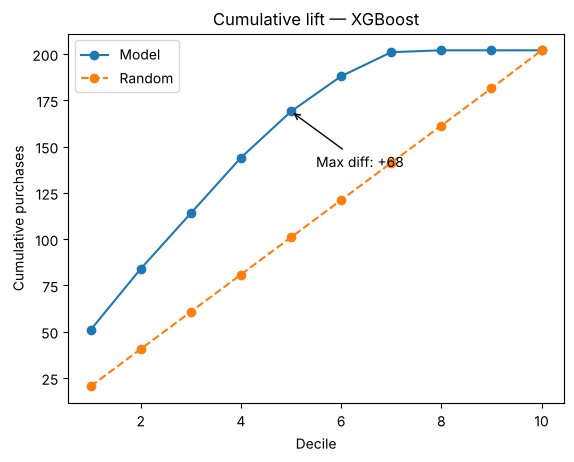

In [17]:
lift_xgb = lift_table(p_xgb)
display(lift_xgb)
plot_lift(lift_xgb, 'Cumulative lift — XGBoost')

---
## 8. Model Comparison

### Task 8.1: Compare Logistic Regression vs XGBoost

Create a summary comparison of both models:
1. Build a summary table with accuracy, sensitivity, specificity, and AUC for both models
2. Plot both ROC curves on the same figure to visually compare discriminative performance

,Logistic,XGBoost
accuracy,0.659,0.771
sensitivity,0.391,0.807
specificity,0.840,0.747
AUC,0.772,0.871


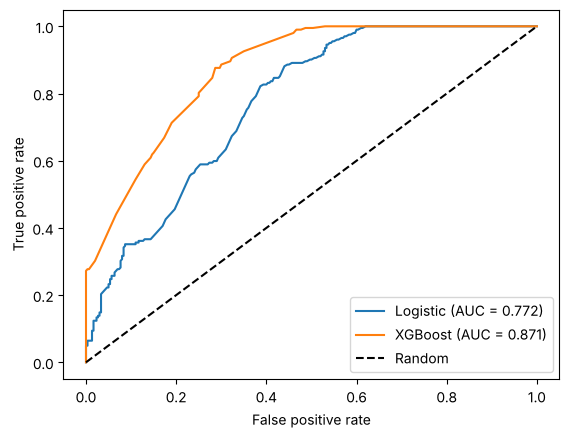

In [18]:
display(pd.DataFrame({'Logistic': [acc_lr, sens_lr, spec_lr, auc_lr],
                      'XGBoost': [acc_xgb, sens_xgb, spec_xgb, auc_xgb]},
                     index=['accuracy', 'sensitivity', 'specificity', 'AUC']).round(3))
plot_roc({'Logistic': p_lr, 'XGBoost': p_xgb})

### Discussion

**Answer the following:**
- Which model performs better overall? Consider accuracy, AUC, sensitivity, and specificity.
- Does XGBoost provide a meaningful improvement over logistic regression for this dataset?
- What are the trade-offs between using logistic regression vs XGBoost? Think about interpretability, ease of explanation to stakeholders, and predictive power.
- Which model would you recommend to a Head of Marketing, and why?

- **Who wins?** On paper XGBoost does: AUC 0.87 vs 0.77, sensitivity 0.81 vs 0.39, accuracy 0.77 vs 0.66. Its lift is also better (2.5× in the top decile, 84% of buyers by decile 5).
- **Is it a real improvement?** Partly. Those numbers are **in-sample**. In cross-validation, XGBoost drops to ~0.68 accuracy, so some of the gap is overfitting. What does hold is the sensitivity jump (0.67 vs 0.38 in CV). It captures the non-linear income effect (very high earners buy less) that the logit can't.
- **Trade-offs:** logit is transparent ("+10k income = +7% odds", "each extra member = +76%") and stable, and it's easy to defend in a meeting. XGBoost predicts better but is a black box, and with 500 rows it overfits easily.
- **Recommendation:** use **XGBoost to score and rank customers**, because it finds more buyers per euro. Use the **logit to explain** who to target and why. If you have to pick just one for a Head of Marketing, I'd go with XGBoost after validating it on a holdout or a pilot campaign, keeping the logit as the narrative.